In [4]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

from IPython.display import display

In [5]:
DATASET_ID = "dipawidia/ecommerce-product-reviews-sentiment"

dataset = load_dataset(DATASET_ID, split="train")
df = dataset.to_pandas()

print("Dataset berhasil dimuat.")
display(df.head())

README.md:   0%|          | 0.00/1.51k [00:00<?, ?B/s]

C:\Users\ASUS Vivobook\AppData\Roaming\Python\Python313\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ASUS Vivobook\.cache\huggingface\hub\datasets--dipawidia--ecommerce-product-reviews-sentiment. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


labeledReview.datasetFix.json:   0%|          | 0.00/3.15M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/11606 [00:00<?, ? examples/s]

Dataset berhasil dimuat.


,review,translate,sentimen
0,Suara dan mic puas. Hanya saya pesan yg nyala ...,sound and mic satisfied. I only ordered the on...,0
1,Good. Mudah-mudahan awet. Makasih,good. hopefully durable. Thanks,1
2,"kondisi dus robek2, tolong di perhatikan lagi","the condition of the box is torn, please pay a...",0
3,Kualitas produk baik. Harga terjangkau dan pen...,product quality is good. affordable prices and...,0
4,"Overall bagus, tombol berfungsi semuanya, tapi...","overall is good, the buttons all work, but the...",0


In [6]:
print("Jumlah data (baris):", df.shape[0])
print("Jumlah kolom:", df.shape[1])
print("\\nNama kolom:")
print(df.columns.tolist())

print("\\nTipe data setiap kolom:")
print(df.dtypes)

print("\\nJumlah data kosong setiap kolom:")
display(df.isna().sum().to_frame("Jumlah data kosong"))

# Pastikan kolom yang diperlukan tersedia
assert "review" in df.columns, "Kolom 'review' tidak ditemukan."
assert "sentimen" in df.columns, "Kolom 'sentimen' tidak ditemukan."

print("\\nDistribusi label sentimen:")
distribusi = df["sentimen"].value_counts(dropna=False).sort_index()
display(distribusi.rename(index={0: "Negatif (0)", 1: "Positif (1)"}).to_frame("Jumlah"))

Jumlah data (baris): 11606
Jumlah kolom: 3
\nNama kolom:
['review', 'translate', 'sentimen']
\nTipe data setiap kolom:
review         str
translate      str
sentimen     int64
dtype: object
\nJumlah data kosong setiap kolom:


,Jumlah data kosong
review,0
translate,0
sentimen,0


\nDistribusi label sentimen:


,Jumlah
sentimen,
Negatif (0),5803
Positif (1),5803


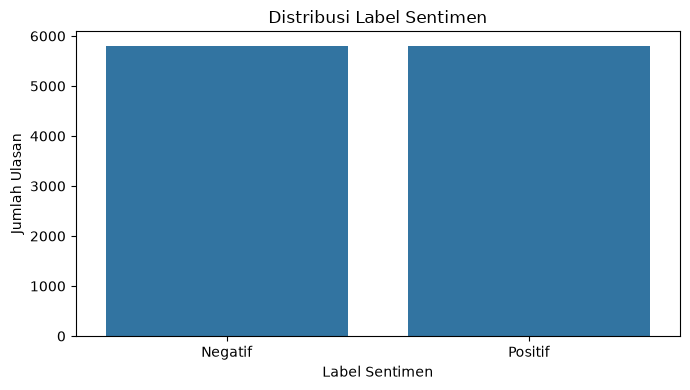

In [7]:
# Visualisasi distribusi label sentimen
label_count = df["sentimen"].value_counts().sort_index()
label_count.index = [("Negatif" if x == 0 else "Positif" if x == 1 else str(x))
                     for x in label_count.index]

plt.figure(figsize=(7, 4))
sns.barplot(x=label_count.index, y=label_count.values)
plt.title("Distribusi Label Sentimen")
plt.xlabel("Label Sentimen")
plt.ylabel("Jumlah Ulasan")
plt.tight_layout()
plt.show()

In [8]:
# Membuat stemmer Bahasa Indonesia
stemmer = StemmerFactory().create_stemmer()

# Membuat daftar stopword Bahasa Indonesia dari Sastrawi
stopwords = set(StopWordRemoverFactory().get_stop_words())

# Pertahankan kata negasi agar makna sentimen tidak hilang
kata_negasi = {"tidak", "bukan", "belum", "jangan"}
stopwords = stopwords - kata_negasi

print("Jumlah stopword yang digunakan:", len(stopwords))

Jumlah stopword yang digunakan: 121


In [9]:
def case_folding(teks):
    """Mengubah seluruh huruf menjadi huruf kecil."""
    return str(teks).lower()

def cleaning(teks):
    """Menghapus URL, angka, tanda baca, karakter khusus, dan spasi berlebih."""
    teks = re.sub(r"https?://\S+|www\.\S+", " ", teks)
    teks = re.sub(r"\d+", " ", teks)
    teks = re.sub(r"[^a-zA-Z\s]", " ", teks)
    teks = re.sub(r"\s+", " ", teks).strip()
    return teks

def tokenisasi(teks):
    """Memisahkan teks menjadi kata."""
    return teks.split()

def stopword_removal(tokens):
    """Menghapus kata yang terdapat dalam daftar stopword."""
    return [kata for kata in tokens if kata not in stopwords]

def stemming(tokens):
    """Mengubah kata berimbuhan menjadi kata dasar."""
    return [stemmer.stem(kata) for kata in tokens]

def preprocessing(teks):
    teks = case_folding(teks)
    teks = cleaning(teks)
    tokens = tokenisasi(teks)
    tokens = stopword_removal(tokens)
    tokens = stemming(tokens)
    return " ".join(tokens)

In [11]:
# Menghapus baris tanpa ulasan
df = df.dropna(subset=["review"]).copy()

# Proses 10 data terlebih dahulu untuk percobaan
df_uji = df.head(10).copy()

df_uji["review_asli"] = df_uji["review"].astype(str)

df_uji["review_preprocessing"] = (
    df_uji["review_asli"].apply(preprocessing)
)

print("Preprocessing 10 data selesai!")

display(
    df_uji[
        ["review_asli", "review_preprocessing", "sentimen"]
    ]
)

Preprocessing 10 data selesai!


,review_asli,review_preprocessing,sentimen
0,Suara dan mic puas. Hanya saya pesan yg nyala ...,suara mic puas pesan yg nyala sy pasti lg klik...,0
1,Good. Mudah-mudahan awet. Makasih,good mudah mudah awet makasih,1
2,"kondisi dus robek2, tolong di perhatikan lagi",kondisi dus robek perhati,0
3,Kualitas produk baik. Harga terjangkau dan pen...,kualitas produk baik harga jangkau kirim cepet...,0
4,"Overall bagus, tombol berfungsi semuanya, tapi...",overall bagus tombol fungsi semua packaging ku...,0
5,"Produk ini original, Dan kualitasnya sangat ba...",produk original kualitas sangat baik cepat kir...,1
6,kualitas sangat jelek. bocor,kualitas sangat jelek bocor,0
7,"terimakasih banyak ka ya, barang sudah diterim...",terimakasih banyak ka barang terima baik sukse...,1
8,"Body nya lebih berat dari cm 1579, spiral nya ...",body nya lebih berat cm spiral nya lebih tipis...,0
9,pesanan di terima tanggal 27 January 2021 teta...,pesan terima tanggal january baru buka pagi ta...,0


In [15]:
# Membuat kolom teks asli
df["review_asli"] = df["review"].astype(str)

# Membuat kolom hasil preprocessing
df["review_preprocessing"] = df["review_asli"].apply(preprocessing)

print(df.columns.tolist())

['review', 'translate', 'sentimen', 'review_asli', 'jumlah_kata_sebelum', 'review_preprocessing']


In [16]:
df["jumlah_kata_sebelum"] = df["review_asli"].apply(lambda x: len(x.split()))
df["jumlah_kata_sesudah"] = df["review_preprocessing"].apply(lambda x: len(x.split()))

print("Jumlah data yang diproses:", len(df))
print("Ulasan yang menjadi kosong setelah preprocessing:",
      (df["review_preprocessing"].str.strip() == "").sum())

display(df[["jumlah_kata_sebelum", "jumlah_kata_sesudah"]].describe())

Jumlah data yang diproses: 11606
Ulasan yang menjadi kosong setelah preprocessing: 5


,jumlah_kata_sebelum,jumlah_kata_sesudah
count,11606.000000,11606.000000
mean,15.756591,13.214458
std,14.412383,11.489655
min,1.000000,0.000000
25%,7.000000,6.000000
50%,12.000000,10.000000
75%,20.000000,17.000000
max,235.000000,167.000000


In [18]:
df.to_csv("hasil_preprocessing_ulasan.csv", index=False, encoding="utf-8-sig")
contoh_10 = df[["review_asli", "review_preprocessing"]].head(10).copy()

display(contoh_10)

print("File berhasil disimpan:")
print("- hasil_preprocessing_ulasan.csv")
print("- 10_contoh_sebelum_sesudah.csv")

,review_asli,review_preprocessing
0,Suara dan mic puas. Hanya saya pesan yg nyala ...,suara mic puas pesan yg nyala sy pasti lg klik...
1,Good. Mudah-mudahan awet. Makasih,good mudah mudah awet makasih
2,"kondisi dus robek2, tolong di perhatikan lagi",kondisi dus robek perhati
3,Kualitas produk baik. Harga terjangkau dan pen...,kualitas produk baik harga jangkau kirim cepet...
4,"Overall bagus, tombol berfungsi semuanya, tapi...",overall bagus tombol fungsi semua packaging ku...
5,"Produk ini original, Dan kualitasnya sangat ba...",produk original kualitas sangat baik cepat kir...
6,kualitas sangat jelek. bocor,kualitas sangat jelek bocor
7,"terimakasih banyak ka ya, barang sudah diterim...",terimakasih banyak ka barang terima baik sukse...
8,"Body nya lebih berat dari cm 1579, spiral nya ...",body nya lebih berat cm spiral nya lebih tipis...
9,pesanan di terima tanggal 27 January 2021 teta...,pesan terima tanggal january baru buka pagi ta...


File berhasil disimpan:
- hasil_preprocessing_ulasan.csv
- 10_contoh_sebelum_sesudah.csv
